# kdd_seq_05_all_in_one_neural_and_comparison: Master Neural Suite & Cross-Method Synthesis

This notebook serves two purposes:
1. **Auto-Runner (`RUN_MISSING_NEURAL = True`)**: If you haven't run `kdd_seq_02`, `03`, and `04` individually yet, this notebook will automatically train and evaluate all three neural approaches (`gru_lm`, `gru_ae`, `gru_cl`) sequentially in one Colab session and save every required artifact to `/content/drive/MyDrive/kdd_seq/results/`.
2. **Cross-Method Comparison & Synthesis**: Loads the Markov mixture (`markov_mixture`) and all three neural approaches (`gru_lm`, `gru_ae`, `gru_cl`), and computes:
   - Clustering quality & volume confounding comparison across $K = 2 \dots 8$ (at both $K = 5$ and $K = 8$).
   - Stability comparison (`seed_ari_mean`, `boot_ari_mean`, train $\rightarrow$ test L1 share shift & dropout correlation).
   - Pairwise **cross-method ARI and NMI matrix** (do different sequence models discover the same behavioural groups?).
   - Downstream dropout prediction comparison (Train 3x3 CV and Real Test Set across all variants + multi-method ensemble fusion).

In [1]:
import os, sys, json, time, warnings
import numpy as np, pandas as pd, scipy.sparse as sp
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from sklearn.model_selection import train_test_split
warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

WORK = "/content/drive/MyDrive/kdd_seq"
sys.path.insert(0, WORK)
import kdd_seq_common as C

# ------------------------------- CONFIG -------------------------------
RUN_MISSING_NEURAL = True   # If True, trains any neural method whose summary_{m}.json is missing
FORCE_RERUN_NEURAL = False  # Set True to retrain all 3 neural methods from scratch
MAX_LEN = 128
BATCH_SIZE = 512
EPOCHS = 15
LR = 3e-3
WEIGHT_DECAY = 1e-4
K_GRID = list(range(2, 9))
K_FINAL = 8
DOWNSTREAM_KS = [5, 8]
CV_SAMPLE, CV_SPLITS, CV_REPEATS = 60000, 3, 3
SEEDS_STAB, N_BOOT = 5, 8
SEED = 42
# ----------------------------------------------------------------------
torch.manual_seed(SEED); np.random.seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
os.makedirs(f"{WORK}/results", exist_ok=True)

A = C.load_artifacts(WORK)
V = A["vocab"]["V"]; NAMES = A["vocab"]["names"]
F_tr, F_te, y_tr, y_te = A["F_train"], A["F_test"], A["y_train"], A["y_test"]
nev_tr, nev_te = A["base_train"]["n_events"].values, A["base_test"]["n_events"].values
print(f"Device: {DEVICE} | Train: {F_tr.shape[0]} | Test: {F_te.shape[0]} | V={V}")


Mounted at /content/drive
Device: cuda | Train: 120542 | Test: 80362 | V=19


In [2]:
# ==============================================================================
# Shared Sequence Packing, Spherical Clustering & Evaluation Helpers
# ==============================================================================
BOS = V          # 19
EOS = V + 1      # 20
PAD = V + 2      # 21
VOCAB_SIZE = V + 3  # 22

def pack_sequences(tokens, offsets, max_len=128):
    """Packs flat CSR sequences (tokens, offsets) into a dense 2D array (N, L_max+2)
    with BOS at index 0, up to max_len most recent tokens (preserving recency), EOS, and PAD."""
    N = len(offsets) - 1
    lengths = np.diff(offsets)
    L_cap = int(min(max_len, lengths.max()))
    out = np.full((N, L_cap + 2), PAD, dtype=np.int64)
    out[:, 0] = BOS
    eff_lens = np.minimum(lengths, L_cap).astype(np.int64)
    for i in range(N):
        s, e = offsets[i], offsets[i + 1]
        L = e - s
        if L > L_cap:
            s = e - L_cap
            L = L_cap
        out[i, 1:1 + L] = tokens[s:e]
        out[i, 1 + L] = EOS
    return out, eff_lens, lengths.astype(np.int64)


class SphericalClusterer:
    """K-Means on L2-normalized embeddings with descending cluster size ordering
    (cluster 0 = largest) and temperature-scaled cosine softmax posteriors."""
    def __init__(self, K, seed=0, n_init=10, temp=0.15):
        self.K = K
        self.seed = seed
        self.n_init = n_init
        self.temp = temp

    def fit(self, Z):
        km = KMeans(self.K, n_init=self.n_init, random_state=self.seed).fit(Z)
        counts = np.bincount(km.labels_, minlength=self.K)
        order = np.argsort(-counts)
        self.centroids_ = km.cluster_centers_[order]
        norms = np.linalg.norm(self.centroids_, axis=1, keepdims=True)
        self.centroids_norm_ = self.centroids_ / np.maximum(norms, 1e-12)
        self.inertia_ = float(km.inertia_)
        return self

    def cosine_sim(self, Z):
        Zn = Z / np.maximum(np.linalg.norm(Z, axis=1, keepdims=True), 1e-12)
        return (Zn @ self.centroids_norm_.T).astype(np.float32)

    def predict_proba(self, Z):
        logits = self.cosine_sim(Z) / self.temp
        logits = logits - logits.max(axis=1, keepdims=True)
        exp_l = np.exp(logits)
        return (exp_l / exp_l.sum(axis=1, keepdims=True)).astype(np.float32)

    def predict(self, Z):
        return self.cosine_sim(Z).argmax(axis=1)


def residualize_volume(Z_tr, Z_te, nev_tr, nev_te, len_tr, len_te):
    """Regresses out log1p(n_events) and log1p(seq_len) from embeddings (fitted on train only),
    then re-normalizes to unit L2 length."""
    X_tr = np.column_stack([np.ones(len(nev_tr)), np.log1p(nev_tr), np.log1p(len_tr)])
    X_te = np.column_stack([np.ones(len(nev_te)), np.log1p(nev_te), np.log1p(len_te)])
    W, _, _, _ = np.linalg.lstsq(X_tr, Z_tr, rcond=None)
    R_tr = Z_tr - X_tr @ W
    R_te = Z_te - X_te @ W
    R_tr /= np.maximum(np.linalg.norm(R_tr, axis=1, keepdims=True), 1e-12)
    R_te /= np.maximum(np.linalg.norm(R_te, axis=1, keepdims=True), 1e-12)
    return R_tr.astype(np.float32), R_te.astype(np.float32)


def describe_clusters_from_F(F, R_soft, V, names, alpha=0.1, cap=50, top=6, min_mass=0.005):
    """Describes any clustering using the empirical transition matrix F[:, V:] in the
    exact same characteristic lift & frequency format as the Markov mixture."""
    K = R_soft.shape[1]
    n = np.asarray(F[:, V:].sum(1)).ravel()
    Fc = (sp.diags(np.minimum(1.0, cap / np.maximum(n, 1))) @ F).tocsr() if cap else F
    S = np.asarray(Fc.T.dot(R_soft)).T[:, V:].reshape(K, V, V)
    G = S.sum(0) + alpha
    Pg = G / G.sum(1, keepdims=True)
    out = {}
    for k in range(K):
        Pk = (S[k] + alpha) / (S[k] + alpha).sum(1, keepdims=True)
        mass = S[k] / np.maximum(S[k].sum(), 1e-12)
        lift = np.where(mass >= min_mass, Pk / Pg, 0)
        li = np.dstack(np.unravel_index(np.argsort(-lift, axis=None)[:top], lift.shape))[0]
        fi = np.dstack(np.unravel_index(np.argsort(-mass, axis=None)[:top], mass.shape))[0]
        out[k] = dict(
            share=float(R_soft[:, k].mean()),
            characteristic=[f"{names[a]} -> {names[b]} (lift {lift[a,b]:.1f})" for a, b in li],
            frequent=[f"{names[a]} -> {names[b]} ({mass[a,b]*100:.1f}%)" for a, b in fi]
        )
    return out

class CausalGRULM(nn.Module):
    def __init__(self, vocab_size=VOCAB_SIZE, d_emb=32, d_hid=64, n_layers=2, dropout=0.1, pad_idx=PAD):
        super().__init__()
        self.pad_idx = pad_idx
        self.emb = nn.Embedding(vocab_size, d_emb, padding_idx=pad_idx)
        self.drop = nn.Dropout(dropout)
        self.gru = nn.GRU(d_emb, d_hid, num_layers=n_layers, batch_first=True,
                          dropout=dropout if n_layers > 1 else 0.0)
        self.head = nn.Linear(d_hid, vocab_size)

    def forward_hidden(self, x):
        h, _ = self.gru(self.drop(self.emb(x)))
        return h

    def loss(self, x):
        inp, tgt = x[:, :-1], x[:, 1:]
        logits = self.head(self.forward_hidden(inp))
        return F.cross_entropy(logits.reshape(-1, logits.size(-1)), tgt.reshape(-1), ignore_index=self.pad_idx)

    @torch.no_grad()
    def encode(self, x):
        inp = x[:, :-1]
        mask = (inp != self.pad_idx).unsqueeze(-1).float()
        h = self.forward_hidden(inp)
        mean_h = (h * mask).sum(1) / mask.sum(1).clamp(min=1.0)
        lengths = mask.squeeze(-1).sum(1).long().clamp(min=1) - 1
        last_h = h[torch.arange(x.size(0), device=x.device), lengths]
        z = 0.5 * F.normalize(mean_h, p=2, dim=-1) + 0.5 * F.normalize(last_h, p=2, dim=-1)
        return F.normalize(z, p=2, dim=-1)

class GRUSeqAutoencoder(nn.Module):
    """Bidirectional GRU Encoder -> 32D L2-Normalized Bottleneck z -> Word-Dropout Conditioned GRU Decoder."""
    def __init__(self, vocab_size=VOCAB_SIZE, d_emb=32, d_hid=64, d_lat=32, dropout=0.1, word_drop=0.4, pad_idx=PAD):
        super().__init__()
        self.pad_idx = pad_idx
        self.word_drop = word_drop
        self.unk_idx = 18
        self.emb = nn.Embedding(vocab_size, d_emb, padding_idx=pad_idx)
        self.drop = nn.Dropout(dropout)
        self.enc_gru = nn.GRU(d_emb, d_hid, num_layers=1, bidirectional=True, batch_first=True)
        self.to_latent = nn.Sequential(nn.Linear(2 * d_hid, d_lat), nn.LayerNorm(d_lat))
        self.from_latent = nn.Linear(d_lat, d_hid)
        self.dec_gru = nn.GRU(d_emb + d_lat, d_hid, num_layers=1, batch_first=True)
        self.head = nn.Linear(d_hid, vocab_size)

    def encode_raw(self, x):
        mask = (x != self.pad_idx).unsqueeze(-1).float()
        h, _ = self.enc_gru(self.drop(self.emb(x)))
        mean_h = (h * mask).sum(1) / mask.sum(1).clamp(min=1.0)
        z = self.to_latent(mean_h)
        return F.normalize(z, p=2, dim=-1)

    def loss(self, x):
        z = self.encode_raw(x)
        inp = x[:, :-1].clone()
        tgt = x[:, 1:]
        if self.training and self.word_drop > 0:
            drop_mask = (torch.rand_like(inp.float()) < self.word_drop) & (inp != self.pad_idx) & (inp != BOS)
            inp[drop_mask] = self.unk_idx
        e = self.drop(self.emb(inp))
        z_rep = z.unsqueeze(1).expand(-1, e.size(1), -1)
        dec_in = torch.cat([e, z_rep], dim=-1)
        h0 = torch.tanh(self.from_latent(z)).unsqueeze(0)
        dec_h, _ = self.dec_gru(dec_in, h0)
        logits = self.head(dec_h)
        return F.cross_entropy(logits.reshape(-1, logits.size(-1)), tgt.reshape(-1), ignore_index=self.pad_idx)

    @torch.no_grad()
    def encode(self, x):
        return self.encode_raw(x)

MODEL_CLS = GRUSeqAutoencoder

def augment_batch_gpu(x, mask_prob=0.15, crop_min=0.6, unk_idx=18, bos_idx=BOS, eos_idx=EOS, pad_idx=PAD):
    """Fast vectorized GPU sequence augmentations:
    1. Random token masking (15% of active tokens -> <unk>)
    2. Random contiguous subsequence cropping (retaining 60-95% of tokens for sequences with L >= 5)"""
    B, T = x.shape
    out = x.clone()
    device = x.device
    active = (out != pad_idx) & (out != bos_idx) & (out != eos_idx)
    lengths = active.sum(dim=1)
    rand_m = torch.rand((B, T), device=device)
    out[active & (rand_m < mask_prob)] = unk_idx
    crop_ratio = crop_min + (0.95 - crop_min) * torch.rand((B, 1), device=device)
    keep_len = torch.clamp((lengths.unsqueeze(1).float() * crop_ratio).long(), min=1)
    max_start = torch.clamp(lengths.unsqueeze(1) - keep_len, min=0)
    start_idx = (torch.rand((B, 1), device=device) * (max_start.float() + 1.0)).long() + 1
    end_idx = start_idx + keep_len
    pos = torch.arange(T, device=device).unsqueeze(0)
    drop_crop = active & (lengths.unsqueeze(1) >= 5) & ((pos < start_idx) | (pos >= end_idx))
    out[drop_crop] = pad_idx
    return out


class ContrastiveGRU(nn.Module):
    """SimCLR / TS2Vec style Contrastive GRU with InfoNCE (NT-Xent) objective."""
    def __init__(self, vocab_size=VOCAB_SIZE, d_emb=32, d_hid=64, d_proj=32, n_layers=2, dropout=0.1, temp=0.1, pad_idx=PAD):
        super().__init__()
        self.pad_idx = pad_idx
        self.temp = temp
        self.emb = nn.Embedding(vocab_size, d_emb, padding_idx=pad_idx)
        self.drop = nn.Dropout(dropout)
        self.gru = nn.GRU(d_emb, d_hid, num_layers=n_layers, batch_first=True,
                          dropout=dropout if n_layers > 1 else 0.0)
        self.proj = nn.Sequential(nn.Linear(d_hid, d_hid), nn.GELU(), nn.Linear(d_hid, d_proj))

    def forward_backbone(self, x):
        mask = (x != self.pad_idx).unsqueeze(-1).float()
        h, _ = self.gru(self.drop(self.emb(x)))
        mean_h = (h * mask).sum(1) / mask.sum(1).clamp(min=1.0)
        return F.normalize(mean_h, p=2, dim=-1)

    def loss(self, x):
        x1 = augment_batch_gpu(x)
        x2 = augment_batch_gpu(x)
        h1, h2 = self.forward_backbone(x1), self.forward_backbone(x2)
        z1 = F.normalize(self.proj(h1), p=2, dim=-1)
        z2 = F.normalize(self.proj(h2), p=2, dim=-1)
        B = z1.size(0)
        z = torch.cat([z1, z2], dim=0)
        sim = torch.matmul(z, z.T) / self.temp
        sim.fill_diagonal_(-1e9)
        targets = torch.cat([torch.arange(B, 2 * B, device=z.device),
                             torch.arange(0, B, device=z.device)], dim=0)
        return F.cross_entropy(sim, targets)

    @torch.no_grad()
    def encode(self, x):
        return self.forward_backbone(x)

MODEL_CLS = ContrastiveGRU


## 1. Autonomous Execution of All Three Neural Methods (`gru_lm`, `gru_ae`, `gru_cl`)

In [3]:
def run_single_neural_experiment(method_name, model_cls, X_tr, X_te, len_tr, len_te):
    print(f"\n======================================================================")
    print(f"STARTING EXPERIMENT: {method_name}")
    print(f"======================================================================")
    torch.manual_seed(SEED); np.random.seed(SEED)
    idx_tr, idx_va = train_test_split(np.arange(len(X_tr)), test_size=0.1, random_state=SEED)
    train_loader = DataLoader(TensorDataset(torch.tensor(X_tr[idx_tr], dtype=torch.long)), batch_size=BATCH_SIZE, shuffle=True)
    val_loader   = DataLoader(TensorDataset(torch.tensor(X_tr[idx_va], dtype=torch.long)), batch_size=BATCH_SIZE * 2, shuffle=False)

    model = model_cls().to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)

    best_val_loss, best_state = np.inf, None
    for ep in range(1, EPOCHS + 1):
        t0 = time.time()
        model.train()
        tr_loss, n_tr = 0.0, 0
        for (bx,) in train_loader:
            bx = bx.to(DEVICE)
            opt.zero_grad()
            loss = model.loss(bx)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            tr_loss += loss.item() * len(bx); n_tr += len(bx)
        sched.step()
        model.eval()
        va_loss, n_va = 0.0, 0
        with torch.no_grad():
            for (bx,) in val_loader:
                bx = bx.to(DEVICE)
                va_loss += model.loss(bx).item() * len(bx); n_va += len(bx)
        tr_loss /= n_tr; va_loss /= n_va
        if va_loss < best_val_loss:
            best_val_loss = va_loss
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        if ep == 1 or ep % 5 == 0 or ep == EPOCHS:
            print(f"[{method_name}] Ep {ep:02d}/{EPOCHS} | train={tr_loss:.4f} | val={va_loss:.4f} | {time.time()-t0:.1f}s")

    model.load_state_dict(best_state)
    model.eval()
    zs_tr, zs_te = [], []
    with torch.no_grad():
        for i in range(0, len(X_tr), 1024):
            zs_tr.append(model.encode(torch.tensor(X_tr[i:i+1024], dtype=torch.long, device=DEVICE)).cpu().numpy())
        for i in range(0, len(X_te), 1024):
            zs_te.append(model.encode(torch.tensor(X_te[i:i+1024], dtype=torch.long, device=DEVICE)).cpu().numpy())
    Z_tr = np.vstack(zs_tr).astype(np.float32)
    Z_te = np.vstack(zs_te).astype(np.float32)
    Z_tr_orth, Z_te_orth = residualize_volume(Z_tr, Z_te, nev_tr, nev_te, len_tr, len_te)

    pca16 = PCA(n_components=min(16, Z_tr.shape[1]), random_state=0).fit(Z_tr)
    Z_tr_pca, Z_te_pca = pca16.transform(Z_tr).astype(np.float32), pca16.transform(Z_te).astype(np.float32)
    pca16_o = PCA(n_components=min(16, Z_tr_orth.shape[1]), random_state=0).fit(Z_tr_orth)
    Z_tr_orth_pca, Z_te_orth_pca = pca16_o.transform(Z_tr_orth).astype(np.float32), pca16_o.transform(Z_te_orth).astype(np.float32)

    rows, models = [], {}
    for K in K_GRID:
        m = SphericalClusterer(K, seed=0, n_init=10).fit(Z_tr)
        models[K] = m
        lab_tr, lab_te = m.predict(Z_tr), m.predict(Z_te)
        P_tr = m.predict_proba(Z_tr)
        r = dict(K=K, inertia=m.inertia_, mean_max_posterior=float(P_tr.max(1).mean()))
        r.update(C.cluster_quality(A["eval_train"], lab_tr))
        nat = C.cluster_quality(Z_tr, lab_tr)
        r["native_silhouette"] = nat["silhouette"]
        r["native_davies_bouldin"] = nat["davies_bouldin"]
        r["native_calinski_harabasz"] = nat["calinski_harabasz"]
        r.update(C.volume_agreement(lab_tr, nev_tr))
        r["cramers_v_train"] = C.cramers_v(lab_tr, y_tr)
        r["cramers_v_test"]  = C.cramers_v(lab_te, y_te)
        rows.append(r)
    grid = pd.DataFrame(rows).set_index("K")
    grid.round(4).to_csv(f"{WORK}/results/{method_name}_grid.csv")

    stab_by_k, cv_all, test_all = {}, [], []
    for K_eval in DOWNSTREAM_KS:
        mk = models[K_eval]
        lab_tr_k, lab_te_k = mk.predict(Z_tr), mk.predict(Z_te)
        desc = describe_clusters_from_F(F_tr, mk.predict_proba(Z_tr), V, NAMES)
        json.dump(desc, open(f"{WORK}/results/{method_name}_cluster_descriptions_K{K_eval}.json", "w"), indent=1)

        seed_labels = [SphericalClusterer(K_eval, seed=100 + s, n_init=5).fit(Z_tr).predict(Z_tr) for s in range(SEEDS_STAB)]
        st = C.seed_stability(seed_labels)
        st.update(C.bootstrap_stability(
            fit=lambda idx, seed: SphericalClusterer(K_eval, seed=seed, n_init=5).fit(Z_tr[idx]),
            predict=lambda cm, rows: cm.predict(Z_tr[rows]),
            n_rows=Z_tr.shape[0], ref_labels=lab_tr_k, n_boot=N_BOOT))
        st.update(C.transfer_consistency(lab_tr_k, y_tr, lab_te_k, y_te, K_eval))
        stab_by_k[K_eval] = {k: round(v, 4) for k, v in st.items()}

        def _vars(Z_a, Z_p, Z_op, sd):
            P = mk.predict_proba(Z_a); lab = P.argmax(1); rng = np.random.default_rng(sd)
            return {"hard": C.onehot(lab, K_eval), "soft": P.astype("float32"),
                    "hard+soft": np.hstack([C.onehot(lab, K_eval), P]).astype("float32"),
                    "cos_sim": mk.cosine_sim(Z_a).astype("float32"),
                    "emb_pca16": Z_p.astype("float32"), "emb_vol_orth": Z_op.astype("float32"),
                    "null_random": C.onehot(rng.integers(0, K_eval, Z_a.shape[0]), K_eval)}

        v_tr, v_te = _vars(Z_tr, Z_tr_pca, Z_tr_orth_pca, 0), _vars(Z_te, Z_te_pca, Z_te_orth_pca, 1)
        summ, _ = C.downstream_cv(A["base_train"], y_tr, v_tr, CV_SAMPLE, CV_SPLITS, CV_REPEATS)
        summ.insert(0, "K", K_eval); summ.insert(0, "method", method_name); cv_all.append(summ)
        ft = C.final_test_eval(A["base_train"], y_tr, A["base_test"], y_te, v_tr, v_te)
        ft.insert(0, "K", K_eval); ft.insert(0, "method", method_name); test_all.append(ft)

        for s, ZZ in (("train", Z_tr), ("test", Z_te)):
            P = mk.predict_proba(ZZ)
            np.save(f"{WORK}/results/feat_{method_name}_K{K_eval}_{s}_soft.npy", P.astype("float32"))
            np.save(f"{WORK}/results/feat_{method_name}_K{K_eval}_{s}_cossim.npy", mk.cosine_sim(ZZ).astype("float32"))
            pd.DataFrame(P, index=A[f"ids_{s}"], columns=[f"p{k}" for k in range(K_eval)]).assign(cluster=P.argmax(1)) \
              .to_csv(f"{WORK}/results/{method_name}_labels_K{K_eval}_{s}.csv", index_label="enrollment_id")

    pd.concat(cv_all).to_csv(f"{WORK}/results/{method_name}_downstream_cv.csv")
    pd.concat(test_all).to_csv(f"{WORK}/results/{method_name}_downstream_test.csv")
    np.save(f"{WORK}/results/feat_{method_name}_train_emb.npy", Z_tr)
    np.save(f"{WORK}/results/feat_{method_name}_test_emb.npy",  Z_te)
    np.save(f"{WORK}/results/feat_{method_name}_train_emb_orth.npy", Z_tr_orth)
    np.save(f"{WORK}/results/feat_{method_name}_test_emb_orth.npy",  Z_te_orth)
    torch.save(model.state_dict(), f"{WORK}/results/{method_name}_weights.pt")

    summary = dict(method=method_name, K=K_FINAL, max_len=MAX_LEN, val_loss=float(best_val_loss))
    summary.update({k: float(v) for k, v in grid.loc[K_FINAL].items()})
    summary.update(stab_by_k[K_FINAL])
    summary["K5_summary"] = {**{k: float(v) for k, v in grid.loc[5].items()}, **stab_by_k[5]}
    json.dump(summary, open(f"{WORK}/results/summary_{method_name}.json", "w"), indent=1)
    print(f"Completed and saved all artifacts for {method_name}!")

if RUN_MISSING_NEURAL:
    X_tr, eff_tr, len_tr = pack_sequences(A["tok_train"], A["off_train"], MAX_LEN)
    X_te, eff_te, len_te = pack_sequences(A["tok_test"],  A["off_test"],  MAX_LEN)
    for m_name, m_cls in [("gru_lm", CausalGRULM), ("gru_ae", GRUSeqAutoencoder), ("gru_cl", ContrastiveGRU)]:
        s_path = f"{WORK}/results/summary_{m_name}.json"
        if FORCE_RERUN_NEURAL or not os.path.exists(s_path):
            run_single_neural_experiment(m_name, m_cls, X_tr, X_te, len_tr, len_te)
        else:
            print(f"Found existing {s_path}, skipping training for {m_name}.")


Found existing /content/drive/MyDrive/kdd_seq/results/summary_gru_lm.json, skipping training for gru_lm.
Found existing /content/drive/MyDrive/kdd_seq/results/summary_gru_ae.json, skipping training for gru_ae.
Found existing /content/drive/MyDrive/kdd_seq/results/summary_gru_cl.json, skipping training for gru_cl.


## 2. Cross-Method Summary Table ($K = 8$ and $K = 5$)
Compares `markov_mixture`, `gru_lm`, `gru_ae`, and `gru_cl` side-by-side on clustering quality, volume independence, stability, and train $\rightarrow$ test transfer.

In [4]:
METHODS = ["markov_mixture", "gru_lm", "gru_ae", "gru_cl"]
summaries_k8, summaries_k5 = [], []

for m in METHODS:
    sp_path = f"{WORK}/results/summary_{'markov' if m == 'markov_mixture' else m}.json"
    if os.path.exists(sp_path):
        s = json.load(open(sp_path))
        k5_sub = s.pop("K5_summary", None)
        summaries_k8.append(s)
        if k5_sub:
            k5_sub["method"] = m; k5_sub["K"] = 5
            summaries_k5.append(k5_sub)
        elif os.path.exists(f"{WORK}/results/markov_grid.csv"):
            mg = pd.read_csv(f"{WORK}/results/markov_grid.csv").set_index("K")
            if 5 in mg.index:
                r5 = mg.loc[5].to_dict(); r5["method"] = m; r5["K"] = 5
                summaries_k5.append(r5)

df_k8 = pd.DataFrame(summaries_k8).set_index("method")
cols_order = [c for c in ["K", "min_cluster_share", "silhouette", "native_silhouette", "davies_bouldin",
                          "calinski_harabasz", "ari_vs_volume", "nmi_vs_volume", "eta2_logvolume",
                          "cramers_v_train", "cramers_v_test", "seed_ari_mean", "boot_ari_mean",
                          "share_L1_train_vs_test", "dropout_corr_train_vs_test"] if c in df_k8.columns]
df_k8 = df_k8[cols_order].round(4)
df_k8.to_csv(f"{WORK}/results/comparison_summary_K8.csv")
print("=== Cross-Method Summary (K=8) ===")
display(df_k8)

if summaries_k5:
    df_k5 = pd.DataFrame(summaries_k5).set_index("method")
    cols_k5 = [c for c in cols_order if c in df_k5.columns]
    df_k5 = df_k5[cols_k5].round(4)
    df_k5.to_csv(f"{WORK}/results/comparison_summary_K5.csv")
    print("\n=== Cross-Method Summary (K=5: Low Volume-Confounding Regime) ===")
    display(df_k5)


=== Cross-Method Summary (K=8) ===


,K,min_cluster_share,silhouette,native_silhouette,davies_bouldin,calinski_harabasz,ari_vs_volume,nmi_vs_volume,eta2_logvolume,cramers_v_train,cramers_v_test,seed_ari_mean,boot_ari_mean,share_L1_train_vs_test,dropout_corr_train_vs_test
method,,,,,,,,,,,,,,,
markov_mixture,8,0.0505,0.1629,NaN,2.7764,1184.4290,0.1747,0.2140,0.2998,0.2157,0.2176,0.7025,0.5509,0.0074,0.9949
gru_lm,8,0.0421,0.2347,0.3487,2.7511,1843.3740,0.2732,0.3504,0.7417,0.3809,0.3740,0.9112,0.8442,0.0102,0.9987
gru_ae,8,0.0520,0.2281,0.2897,3.5139,1845.7944,0.4204,0.5512,0.9156,0.4719,0.4640,0.9406,0.9381,0.0051,0.9999
gru_cl,8,0.0585,0.1899,0.3848,5.7591,1142.2637,0.4987,0.6295,0.9423,0.4983,0.4916,0.8719,0.8474,0.0077,0.9999



=== Cross-Method Summary (K=5: Low Volume-Confounding Regime) ===


,K,min_cluster_share,silhouette,native_silhouette,davies_bouldin,calinski_harabasz,ari_vs_volume,nmi_vs_volume,eta2_logvolume,cramers_v_train,cramers_v_test,seed_ari_mean,boot_ari_mean,share_L1_train_vs_test,dropout_corr_train_vs_test
method,,,,,,,,,,,,,,,
markov_mixture,5,0.0727,0.1061,NaN,2.9915,918.6956,0.0708,0.0968,0.1489,0.1062,0.1022,NaN,NaN,NaN,NaN
gru_lm,5,0.0704,0.2374,0.3398,2.7447,2504.2761,0.3768,0.4188,0.7355,0.3770,0.3759,0.9988,0.9941,0.0070,0.9997
gru_ae,5,0.0572,0.2504,0.3113,2.7516,2687.3413,0.5776,0.6312,0.8846,0.4434,0.4377,0.7916,0.8295,0.0026,0.9999
gru_cl,5,0.1693,0.1878,0.4060,4.8664,1712.6860,0.6438,0.6906,0.9265,0.4927,0.4860,1.0000,0.9948,0.0033,0.9998


## 3. Pairwise Cluster Agreement Across Methods (ARI & NMI Matrix)
Tests whether the neural models and the Markov mixture partition learners into the same behavioural groups or capture distinct structural axes.

In [5]:
labels_k8 = {}
for m in METHODS:
    prefix = "markov" if m == "markov_mixture" else m
    lp = f"{WORK}/results/{prefix}_labels_K8_train.csv"
    if os.path.exists(lp):
        labels_k8[m] = pd.read_csv(lp)["cluster"].values

if len(labels_k8) >= 2:
    m_names = list(labels_k8.keys())
    ari_mat = pd.DataFrame(index=m_names, columns=m_names, dtype=float)
    nmi_mat = pd.DataFrame(index=m_names, columns=m_names, dtype=float)
    for m1 in m_names:
        for m2 in m_names:
            ari_mat.loc[m1, m2] = adjusted_rand_score(labels_k8[m1], labels_k8[m2])
            nmi_mat.loc[m1, m2] = normalized_mutual_info_score(labels_k8[m1], labels_k8[m2])
    ari_mat.round(4).to_csv(f"{WORK}/results/comparison_pairwise_ari_K8.csv")
    nmi_mat.round(4).to_csv(f"{WORK}/results/comparison_pairwise_nmi_K8.csv")
    print("=== Pairwise Adjusted Rand Index (ARI) on Train (K=8) ===")
    display(ari_mat.round(4))
    print("=== Pairwise Normalized Mutual Information (NMI) on Train (K=8) ===")
    display(nmi_mat.round(4))


=== Pairwise Adjusted Rand Index (ARI) on Train (K=8) ===


,markov_mixture,gru_lm,gru_ae,gru_cl
markov_mixture,1.0000,0.4068,0.3557,0.2802
gru_lm,0.4068,1.0000,0.4755,0.4024
gru_ae,0.3557,0.4755,1.0000,0.5395
gru_cl,0.2802,0.4024,0.5395,1.0000


=== Pairwise Normalized Mutual Information (NMI) on Train (K=8) ===


,markov_mixture,gru_lm,gru_ae,gru_cl
markov_mixture,1.0000,0.4374,0.3541,0.2445
gru_lm,0.4374,1.0000,0.4682,0.3800
gru_ae,0.3541,0.4682,1.0000,0.5963
gru_cl,0.2445,0.3800,0.5963,1.0000


## 4. Downstream Dropout Prediction Comparison & Multi-Method Fusion
Consolidates all CV and Real Test evaluations and runs an additional **Multi-Method Fusion** experiment combining `markov_soft + gru_lm_pca16 + gru_ae_pca16 + gru_cl_pca16`.

In [6]:
cv_tables = []
for m in ["markov", "gru_lm", "gru_ae", "gru_cl"]:
    p = f"{WORK}/results/{m}_downstream_cv.csv"
    if os.path.exists(p):
        df = pd.read_csv(p)
        if "method" not in df.columns:
            df.insert(0, "method", "markov_mixture")
        cv_tables.append(df)

if cv_tables:
    all_cv = pd.concat(cv_tables, ignore_index=True)
    all_cv.to_csv(f"{WORK}/results/comparison_all_downstream_cv.csv", index=False)
    print("=== Consolidated Downstream Train CV Results ===")
    display(all_cv)

# Multi-Method Feature Fusion Evaluation (combining Markov + all 3 Neural Representations)
fusion_tr, fusion_te = {}, {}
if os.path.exists(f"{WORK}/results/feat_markov_K8_train_soft.npy"):
    fusion_tr["markov_soft"] = np.load(f"{WORK}/results/feat_markov_K8_train_soft.npy")
    fusion_te["markov_soft"] = np.load(f"{WORK}/results/feat_markov_K8_test_soft.npy")

neural_tr_list, neural_te_list = [], []
for m in ["gru_lm", "gru_ae", "gru_cl"]:
    p_tr = f"{WORK}/results/feat_{m}_train_emb.npy"
    p_te = f"{WORK}/results/feat_{m}_test_emb.npy"
    if os.path.exists(p_tr) and os.path.exists(p_te):
        ztr, zte = np.load(p_tr), np.load(p_te)
        pca = PCA(n_components=8, random_state=0).fit(ztr)
        fusion_tr[f"{m}_pca8"] = pca.transform(ztr).astype(np.float32)
        fusion_te[f"{m}_pca8"] = pca.transform(zte).astype(np.float32)
        neural_tr_list.append(fusion_tr[f"{m}_pca8"])
        neural_te_list.append(fusion_te[f"{m}_pca8"])

if len(neural_tr_list) == 3:
    fusion_tr["all_neural_pca24"] = np.hstack(neural_tr_list)
    fusion_te["all_neural_pca24"] = np.hstack(neural_te_list)
    if "markov_soft" in fusion_tr:
        fusion_tr["markov_plus_all_neural"] = np.hstack([fusion_tr["markov_soft"]] + neural_tr_list)
        fusion_te["markov_plus_all_neural"] = np.hstack([fusion_te["markov_soft"]] + neural_te_list)

    print("\n=== Running Multi-Method Fusion Downstream Evaluation ===")
    f_cv, _ = C.downstream_cv(A["base_train"], y_tr, fusion_tr, CV_SAMPLE, CV_SPLITS, CV_REPEATS)
    f_te = C.final_test_eval(A["base_train"], y_tr, A["base_test"], y_te, fusion_tr, fusion_te)
    f_cv.to_csv(f"{WORK}/results/comparison_fusion_cv.csv")
    f_te.to_csv(f"{WORK}/results/comparison_fusion_test.csv")
    print("=== Fusion Train CV ==="); display(f_cv)
    print("=== Fusion Real TEST Set ==="); display(f_te)


=== Consolidated Downstream Train CV Results ===


,method,variant,K,auc_mean,auc_std,delta_vs_base,delta_std,folds_better
0,markov_mixture,baseline,8,0.85318,0.00205,0.00000,0.00000,0
1,markov_mixture,hard,8,0.85357,0.00198,0.00038,0.00048,8
2,markov_mixture,soft,8,0.85354,0.00208,0.00035,0.00048,7
3,markov_mixture,hard+soft,8,0.85337,0.00235,0.00018,0.00060,6
4,markov_mixture,avgll,8,0.85342,0.00222,0.00024,0.00059,5
5,markov_mixture,null_random,8,0.85319,0.00190,0.00001,0.00051,5
6,gru_lm,baseline,5,0.85318,0.00205,0.00000,0.00000,0
7,gru_lm,hard,5,0.85302,0.00217,-0.00017,0.00050,3
8,gru_lm,soft,5,0.85287,0.00210,-0.00031,0.00039,3
9,gru_lm,hard+soft,5,0.85296,0.00218,-0.00022,0.00057,4



=== Running Multi-Method Fusion Downstream Evaluation ===
=== Fusion Train CV ===


,auc_mean,auc_std,delta_vs_base,delta_std,folds_better
variant,,,,,
baseline,0.85318,0.00205,0.00000,0.00000,0
markov_soft,0.85354,0.00208,0.00035,0.00048,7
gru_lm_pca8,0.85315,0.00197,-0.00003,0.00112,6
gru_ae_pca8,0.85293,0.00243,-0.00025,0.00068,4
gru_cl_pca8,0.85278,0.00201,-0.00040,0.00061,3
all_neural_pca24,0.85308,0.00224,-0.00010,0.00108,4
markov_plus_all_neural,0.85302,0.00197,-0.00016,0.00077,5


=== Fusion Real TEST Set ===


auc                ap                f1           \
                           mean      std     mean      std     mean      std   
variant                                                                        
baseline                0.85305  0.00006  0.94705  0.00008  0.91002  0.00028   
markov_soft             0.85386  0.00010  0.94725  0.00004  0.91064  0.00009   
gru_lm_pca8             0.85301  0.00019  0.94692  0.00002  0.91003  0.00078   
gru_ae_pca8             0.85309  0.00023  0.94693  0.00008  0.90993  0.00021   
gru_cl_pca8             0.85308  0.00008  0.94710  0.00002  0.90986  0.00010   
all_neural_pca24        0.85322  0.00021  0.94701  0.00007  0.91011  0.00038   
markov_plus_all_neural  0.85353  0.00010  0.94703  0.00004  0.91028  0.00046   

                       auc_delta_vs_base  
                                          
variant                                   
baseline                         0.00000  
markov_soft                      0.00081  
gru_lm_pca8                     -0.00004  
gru_ae_pca8                      0.00004  
gru_cl_pca8                      0.00003  
all_neural_pca24                 0.00017  
markov_plus_all_neural           0.00048

## 5. Cross-Method Diagnostic Plots across $K = 2 \dots 8$

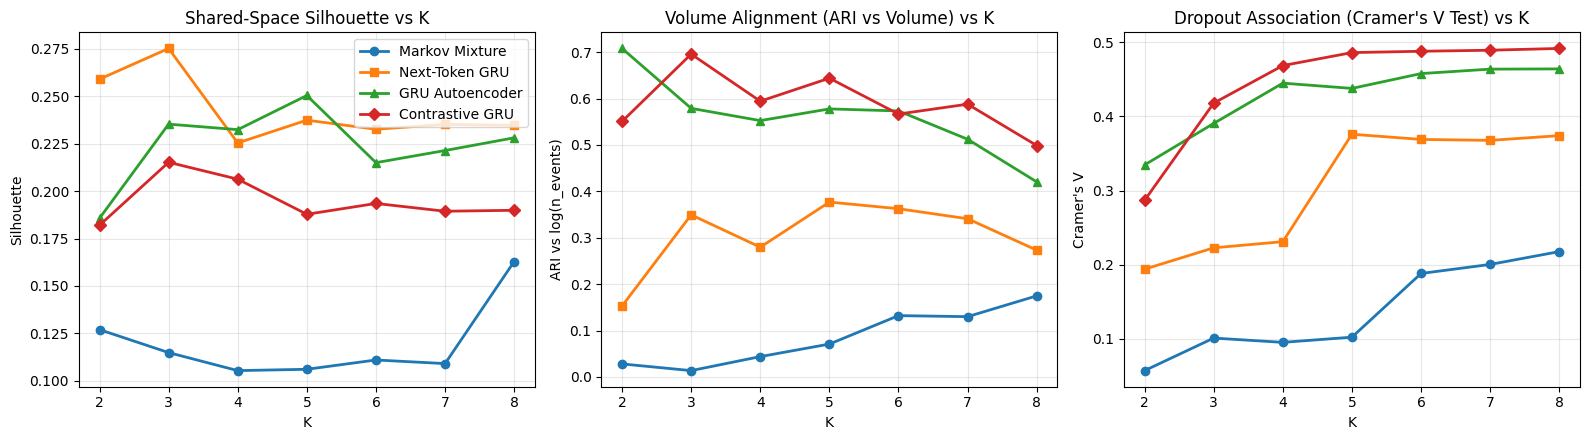

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for m, label, marker in [("markov", "Markov Mixture", "o"), ("gru_lm", "Next-Token GRU", "s"),
                         ("gru_ae", "GRU Autoencoder", "^"), ("gru_cl", "Contrastive GRU", "D")]:
    gp = f"{WORK}/results/{m}_grid.csv"
    if os.path.exists(gp):
        g = pd.read_csv(gp)
        axes[0].plot(g["K"], g["silhouette"], marker=marker, lw=2, label=label)
        axes[1].plot(g["K"], g["ari_vs_volume"], marker=marker, lw=2, label=label)
        axes[2].plot(g["K"], g["cramers_v_test"], marker=marker, lw=2, label=label)

axes[0].set_title("Shared-Space Silhouette vs K"); axes[0].set_xlabel("K"); axes[0].set_ylabel("Silhouette"); axes[0].grid(alpha=0.3); axes[0].legend()
axes[1].set_title("Volume Alignment (ARI vs Volume) vs K"); axes[1].set_xlabel("K"); axes[1].set_ylabel("ARI vs log(n_events)"); axes[1].grid(alpha=0.3)
axes[2].set_title("Dropout Association (Cramer's V Test) vs K"); axes[2].set_xlabel("K"); axes[2].set_ylabel("Cramer's V"); axes[2].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{WORK}/results/comparison_metrics_across_K.png", dpi=150)
plt.show()
